# Validate against buoy observations

Compare **bulk metamodel**, **spectral metamodel**, and **dynamic SnapWave** to Lauri buoy records.

**Prerequisites**

1. Fitted models — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Dynamic run for the same period — `08_Dynamic_Cases_Generation.ipynb`
3. Processed buoy pickles under `inputs/LauriBuoys/processed/`

Use the **same `period`** for buoy data, reconstruction, and dynamic output.

In [1]:
import matplotlib.pyplot as plt
import xarray as xr
from utils import metamodel as mm
from utils import validation as val
from utils.config import SIMULATIONS, resolve

## Configuration

Map each SnapWave buoy site to a processed pickle. Keys must match mesh site ids
(e.g. `buoy_Apolima_Buoy`). Set `period` to overlap buoy records and dynamic output.

In [2]:
period = "1989-09"  # e.g. "1990-05" or "2020-05" — must match buoy + dynamic
offshore_name = "WHACS"
mda_n = 450
pca_variance = {"hs": 0.95, "dir": 0.95}

# Buoy sites to validate (subset of buoy_files keys)
sites = ["buoy_Apolima_Buoy"]

# SnapWave site id → LauriBuoys processed pickle
buoy_files = {
    "buoy_Apolima_Buoy": (
        "inputs/LauriBuoys/processed/samoaapolima_lon187.8_lat-13.88_year1989_1990.pkl"
    ),
    # "buoy_Aunuu_Buoy": "inputs/LauriBuoys/processed/<your_file>.pkl",
}

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"])
    / f"Dynamic_Cases_{offshore_name}_198909_199004_2020.nc"
)

# Buoy pickles may lack direction — compare hs/tp only unless dir is present
variables = ["hs", "tp"]

print(f"period        : {period}")
print(f"mda_n         : {mda_n}")
print(f"sites         : {sites}")
print(f"dynamic path  : {dynamic_path}")
print(f"dynamic exists: {dynamic_path.is_file()}")

period        : 1989-09
mda_n         : 450
sites         : ['buoy_Apolima_Buoy']
dynamic path  : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_198909_199004_2020.nc
dynamic exists: True


## 1 · Check models

In [3]:
mm.require_models_all(mda_n, pca_variance=pca_variance)

## 2 · Load buoy observations

In [4]:
buoy_files_active = {k: buoy_files[k] for k in sites}
buoy = val.load_buoy_observations(buoy_files_active, time=period)
buoy

2026-06-30 12:20:50,795 - Samoa.validation - INFO - Loaded buoy data: 1 site(s), 344 time step(s)


<xarray.Dataset> Size: 8kB
Dimensions:  (time: 344, sites: 1)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1989-09-01T01:30:00 ... 1989-09-30T23:...
  * sites    (sites) object 8B 'buoy_Apolima_Buoy'
Data variables:
    hs       (time, sites) float64 3kB 1.63 1.74 1.74 1.74 ... 2.46 2.32 2.18
    tp       (time, sites) float64 3kB 12.1 11.4 6.6 6.9 ... 10.3 10.3 10.3 10.3

## 3 · Reconstruct metamodel and load dynamic

In [5]:
bulk = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)

spectral = mm.reconstruct(
    period,
    mda_n,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)

if not dynamic_path.is_file():
    raise FileNotFoundError(
        f"Dynamic output not found: {dynamic_path}\n"
        "Run 08_Dynamic_Cases_Generation for this period or change `period`."
    )

dynamic = xr.open_dataset(dynamic_path).sel(time="1989-09")
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids)[["hs", "tp", "dir"]].load()

estimates = {
    "Bulk metamodel": bulk[[v for v in variables if v in bulk]],
    "Spectral metamodel": spectral[[v for v in variables if v in spectral]],
    "Dynamic SnapWave": dynamic[[v for v in variables if v in dynamic]],
}

2026-06-30 12:21:13,552 - Samoa.metamodel - INFO - Reconstruct time='1989-09' n=450 goals=['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11'] partitions=[-1] sites=1
INFO:ExactGPInterpolation:Preprocessing dataset for prediction
INFO:ExactGPInterpolation:Checking for NaNs in subset data
INFO:ExactGPInterpolation:Preprocessing subset data
INFO:ExactGPInterpolation:Normalizing subset data
INFO:ExactGPInterpolation:Proposed max custom scaler for tp is lower than datapoint
INFO:ExactGPInterpolation:Proposed max custom scaler for spr is lower than datapoint
INFO:ExactGPInterpolation:Proposed max custom scaler for dir_u is lower than datapoint
INFO:ExactGPInterpolation:Proposed min custom scaler for dir_v is bigger than datapoint
INFO:ExactGPInterpolation:Subset data preprocessed successfully
INFO:ExactGPInterpolation:Predicting target variable: hs__PC1
INFO:ExactGPInterpolation:Predicting target variable: hs__PC2
INFO:ExactGPInterpolation:Predicting target variable: hs__PC3
INFO:Exact

## 4 · Metrics vs buoy

In [6]:
results = val.compare_all(
    buoy,
    estimates,
    sites=sites,
    variables=variables,
    reference_label="Buoy",
)

summary = val.metrics_summary(results)
summary

2026-06-30 12:22:16,501 - Samoa.validation - INFO - Computed 2 validation metric row(s)
2026-06-30 12:22:16,509 - Samoa.validation - INFO - Computed 2 validation metric row(s)
2026-06-30 12:22:16,516 - Samoa.validation - INFO - Computed 2 validation metric row(s)


,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label,model
0,buoy_Apolima_Buoy,buoy,waves,hs,Hs,171,-0.799028,1.000442,-16.954029,Bulk metamodel,Buoy,Bulk metamodel
1,buoy_Apolima_Buoy,buoy,waves,tp,Tp,171,-1.453889,2.887257,-1.221951,Bulk metamodel,Buoy,Bulk metamodel
2,buoy_Apolima_Buoy,buoy,waves,hs,Hs,171,-0.725342,0.902915,-17.678787,Spectral metamodel,Buoy,Spectral metamodel
3,buoy_Apolima_Buoy,buoy,waves,tp,Tp,171,-2.819622,3.604726,-21.168620,Spectral metamodel,Buoy,Spectral metamodel
4,buoy_Apolima_Buoy,buoy,waves,hs,Hs,171,-1.148448,1.246698,-157.918886,Dynamic SnapWave,Buoy,Dynamic SnapWave
5,buoy_Apolima_Buoy,buoy,waves,tp,Tp,171,-0.950429,2.289067,-1.497841,Dynamic SnapWave,Buoy,Dynamic SnapWave


## 5 · Scatter plots

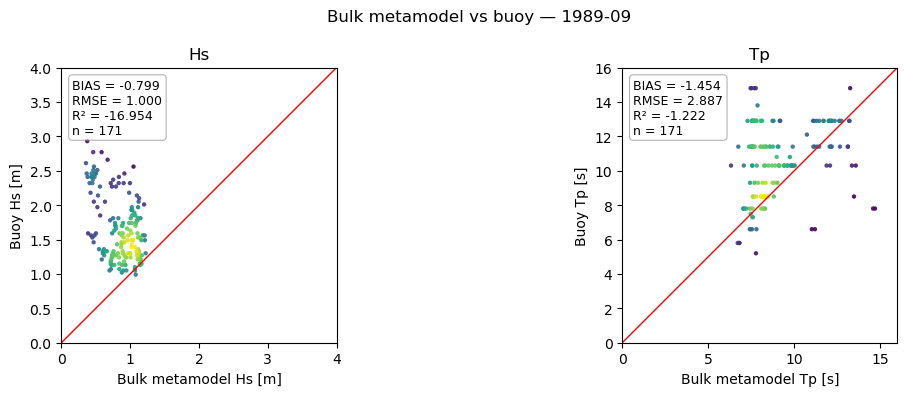

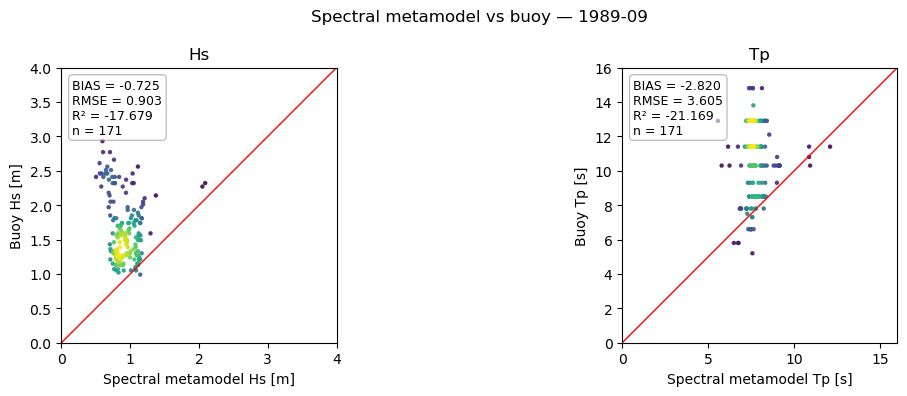

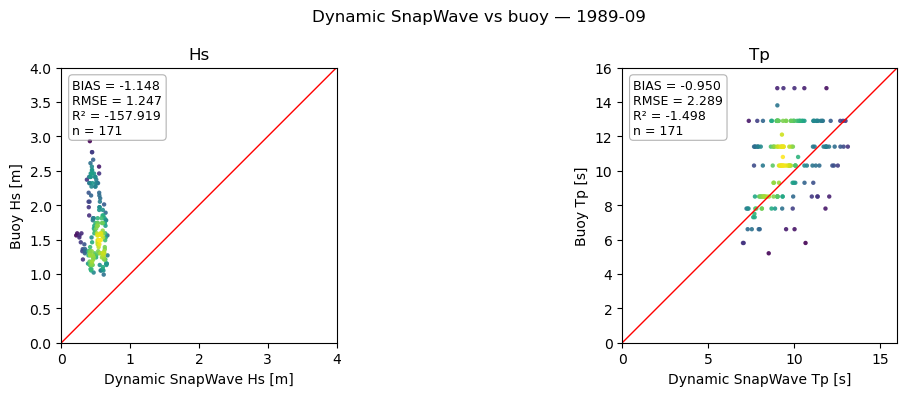

In [7]:
group = mm.resolve_sites(estimates["Bulk metamodel"], sites)[0]

for name, result in results.items():
    result.plot_scatter(
        group,
        variables=variables,
        estimate_label=name,
        reference_label="Buoy",
    )
    plt.suptitle(f"{name} vs buoy — {period}")
    plt.show()